<a href="https://colab.research.google.com/github/arxsyy/PCVK_Ganjil_2026/blob/main/Week7_Segmentasi_dan_Thresholding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Folder gambar di Drive
PATH = '/content/drive/MyDrive/PCVK/'

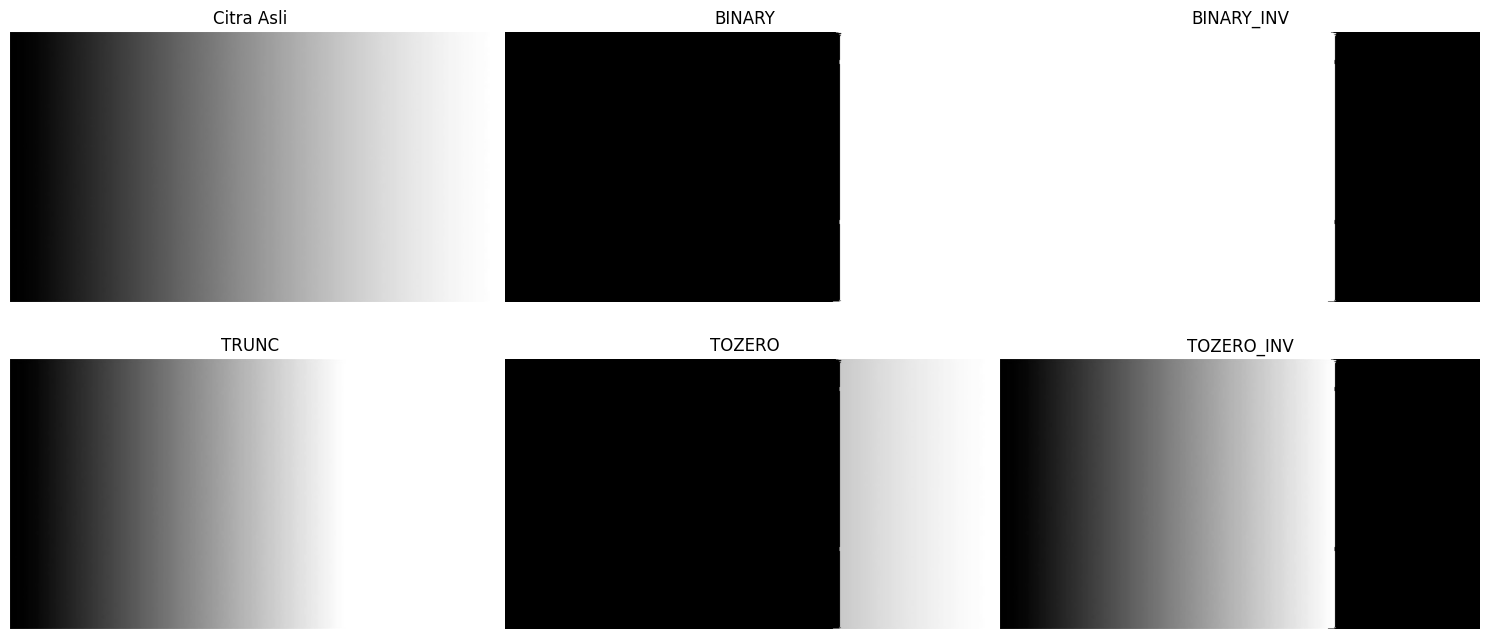

In [9]:
img = cv.imread(PATH + 'Images/gradient.jpg', 0)

thresh = 200
maxval = 255

# BINARY
thresh1 = np.zeros_like(img)
thresh1[img > thresh] = maxval

# BINARY_INV
thresh2 = np.zeros_like(img)
thresh2[img <= thresh] = maxval

# TRUNC
thresh3 = img.copy()
thresh3[img > thresh] = thresh

# TOZERO
thresh4 = img.copy()
thresh4[img <= thresh] = 0

# TOZERO_INV
thresh5 = img.copy()
thresh5[img > thresh] = 0

images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]
titles = ['Citra Asli', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

plt.figure(figsize=(15, 7))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Adaptive Threshold manual

Citra yang digunakan adalah `sudoku-original.jpg`. Ambang lokal dihitung dari jendela **11×11**, dengan **C = 2**. Untuk Gaussian, kernel dibuat sendiri dengan **sigma = 2**. Bagian ini tidak menggunakan `cv.threshold()`, `cv.adaptiveThreshold()`, atau fungsi filter siap pakai.


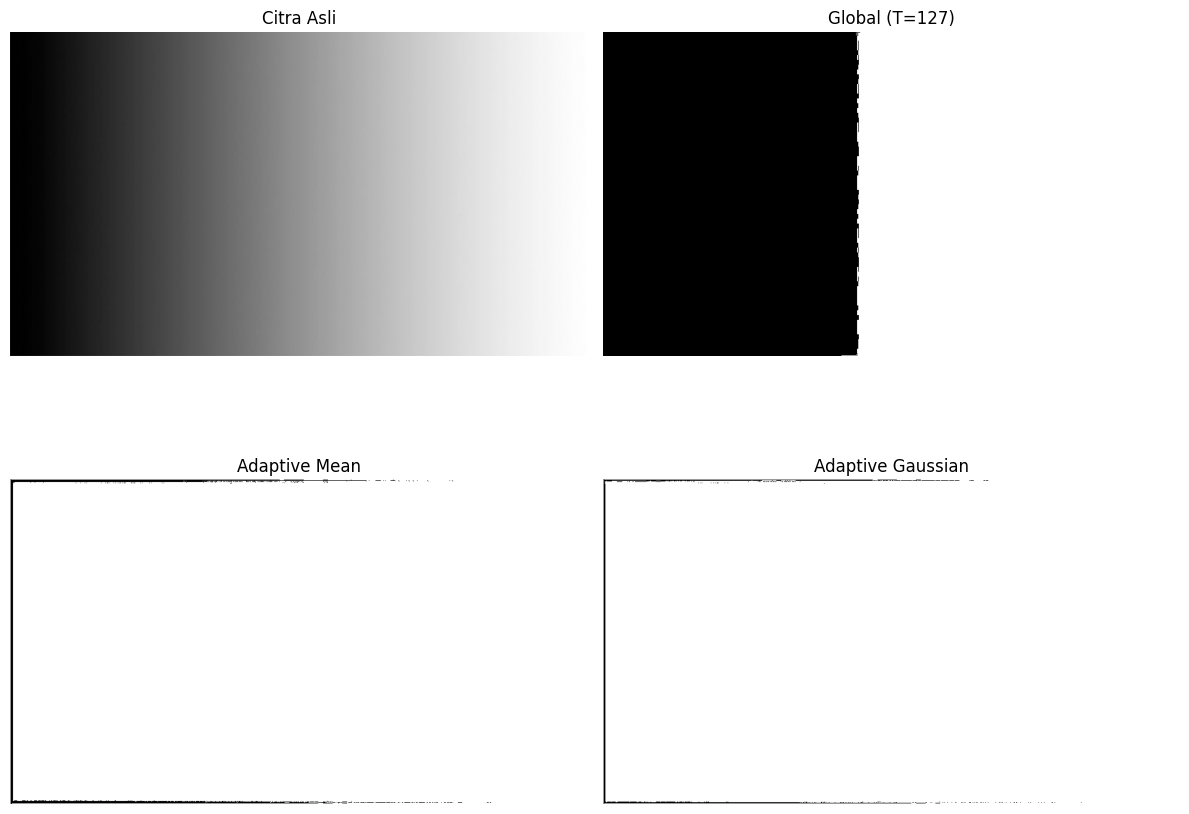

In [10]:
img = cv.imread(PATH + 'Images/gradient.jpg', 0)

# Global threshold manual, T = 127
global_127 = np.zeros_like(img)
global_127[img > 127] = 255

ukuran = 11
C = 2
sigma = 2
r = ukuran // 2
img_pad = np.pad(img, ((r, r), (r, r)), mode='edge')

# Adaptive Mean manual
adaptive_mean = np.zeros_like(img)
for y in range(img.shape[0]):
    for x in range(img.shape[1]):
        area = img_pad[y:y + ukuran, x:x + ukuran]
        T = np.mean(area) - C
        if img[y, x] > T:
            adaptive_mean[y, x] = 255

# Membuat kernel Gaussian 11 x 11
koordinat = np.arange(-r, r + 1)
X, Y = np.meshgrid(koordinat, koordinat)
kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
kernel = kernel / kernel.sum()

# Adaptive Gaussian manual
adaptive_gaussian = np.zeros_like(img)
for y in range(img.shape[0]):
    for x in range(img.shape[1]):
        area = img_pad[y:y + ukuran, x:x + ukuran]
        T = np.sum(area * kernel) - C
        if img[y, x] > T:
            adaptive_gaussian[y, x] = 255

images = [img, global_127, adaptive_mean, adaptive_gaussian]
titles = ['Citra Asli', 'Global (T=127)', 'Adaptive Mean', 'Adaptive Gaussian']

plt.figure(figsize=(12, 10))
for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()


## 5A. Otsu Thresholding manual pada Lena

Otsu mencari ambang yang menghasilkan variansi antar-kelas terbesar. Setelah itu, hasilnya dibandingkan dengan Otsu dari OpenCV


Threshold global = 127
Threshold Otsu manual = 92
Threshold Otsu OpenCV = 92


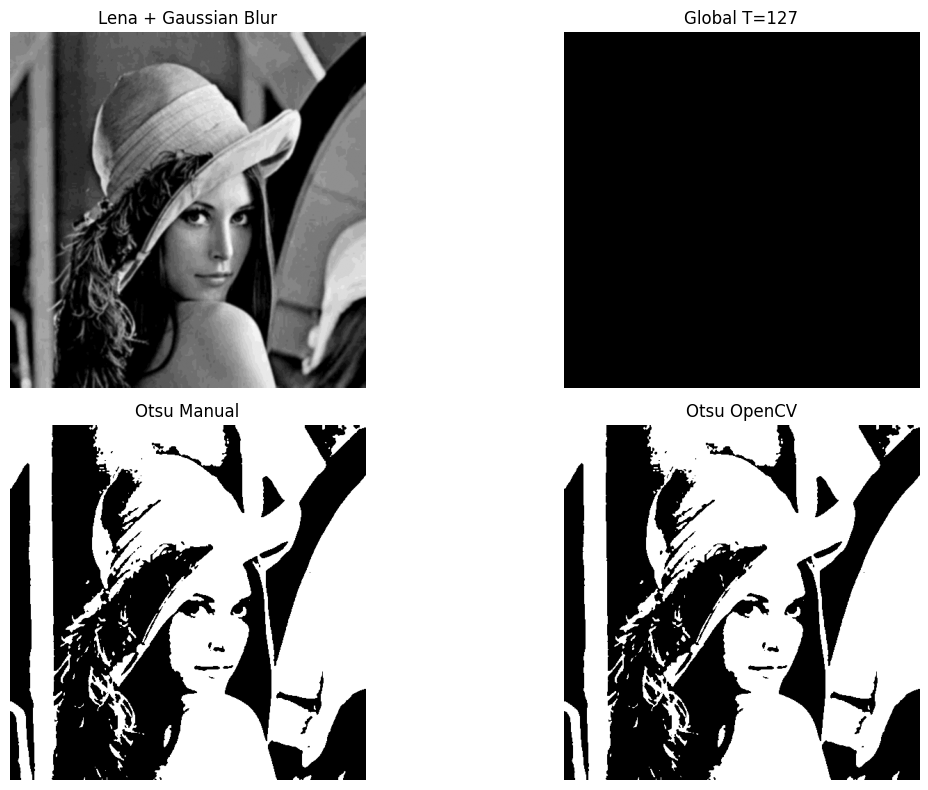

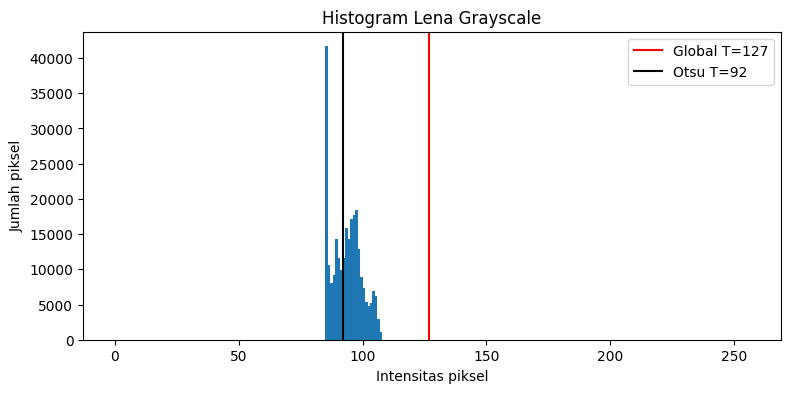

In [12]:
def otsu(gray):
    hist, _ = np.histogram(gray, bins=256, range=(0, 256))
    total = gray.size
    jumlah_total = sum(i * hist[i] for i in range(256))

    jumlah_bg = 0
    berat_bg = 0
    variansi_terbesar = 0
    ambang = 0

    for t in range(256):
        berat_bg += hist[t]
        if berat_bg == 0:
            continue

        berat_fg = total - berat_bg
        if berat_fg == 0:
            break

        jumlah_bg += t * hist[t]
        mean_bg = jumlah_bg / berat_bg
        mean_fg = (jumlah_total - jumlah_bg) / berat_fg
        variansi = berat_bg * berat_fg * (mean_bg - mean_fg) ** 2

        if variansi > variansi_terbesar:
            variansi_terbesar = variansi
            ambang = t

    hasil = np.zeros_like(gray)
    hasil[gray > ambang] = 255
    return hasil, ambang

img = cv.imread(PATH + 'Images/lena_gs_lc2.jpg', 0)
blur = cv.GaussianBlur(img, (5, 5), 0)

# Global threshold manual T = 127
global_lena = np.zeros_like(blur)
global_lena[blur > 127] = 255

otsu_lena, T_otsu = otsu(blur)
T_cv, otsu_cv = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

print('Threshold global = 127')
print('Threshold Otsu manual =', T_otsu)
print('Threshold Otsu OpenCV =', int(T_cv))

images = [blur, global_lena, otsu_lena, otsu_cv]
titles = ['Lena + Gaussian Blur', 'Global T=127', 'Otsu Manual', 'Otsu OpenCV']
plt.figure(figsize=(13, 8))
for i in range(len(images)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

# Histogram untuk melihat letak ambang
plt.figure(figsize=(9, 4))
plt.hist(blur.ravel(), bins=256, range=(0, 256))
plt.axvline(127, color='red', label='Global T=127')
plt.axvline(T_otsu, color='black', label='Otsu T=' + str(T_otsu))
plt.title('Histogram Lena Grayscale')
plt.xlabel('Intensitas piksel')
plt.ylabel('Jumlah piksel')
plt.legend()
plt.show()

**Analisis pertanyaan Lena:** nilai intensitas citra Lena low-contrast pada contoh modul berada kira-kira di rentang 85–108. Karena semuanya berada di bawah 127, global binary threshold dengan T = 127 mengubahnya menjadi hitam. Pada contoh modul, Otsu menghasilkan ambang sekitar 92; nilai yang muncul dari file praktikum kamu ditampilkan pada output di atas. Periksa histogram untuk melihat bahwa ambang Otsu berada di dalam sebaran intensitas citra.

### 5B. Bandingkan Global dan Otsu pada gambar KTP sendiri

Saving KTM1a.jpg to KTM1a.jpg
Threshold global = 127
Threshold Otsu KTP = 51


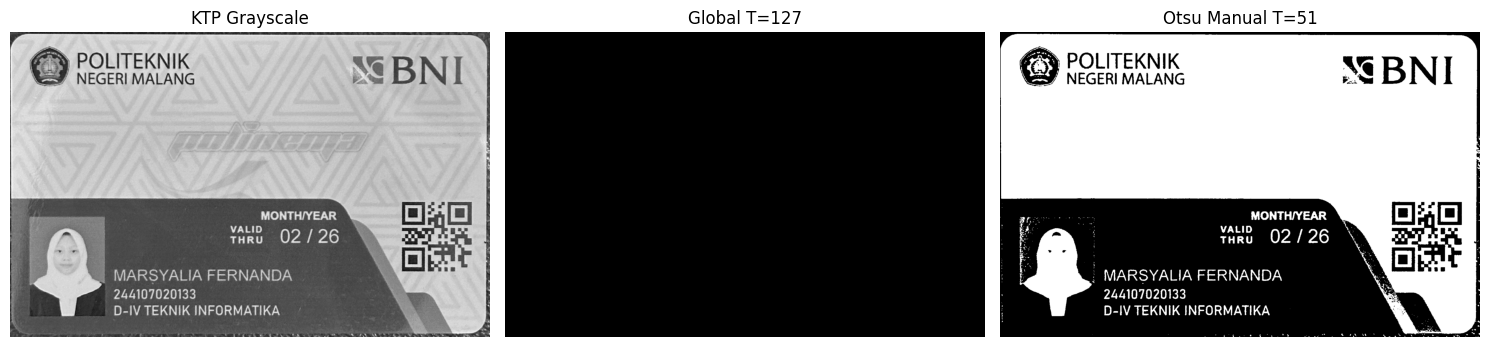

In [15]:
from google.colab import files

uploaded = files.upload()
ktp_nama = list(uploaded.keys())[0]
ktp_bgr = cv.imread(ktp_nama)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)

# Global threshold manual T = 127
ktp_global = np.zeros_like(ktp_gray)
ktp_global[ktp_gray > 127] = 255

ktp_otsu, T_ktp = otsu(ktp_gray)

print("Threshold global = 127")
print("Threshold Otsu KTP =", T_ktp)

images = [ktp_gray, ktp_global, ktp_otsu]
titles = ["KTP Grayscale", "Global T=127", "Otsu Manual T=" + str(T_ktp)]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
  plt.subplot(1, 3, i + 1)
  plt.imshow(images[i], cmap="gray")
  plt.title(titles[i])
  plt.axis("off")
plt.tight_layout()
plt.show()

### 6A. Region Growing manual pada `data.coins()`

Seed yang dipakai: satu di dalam koin, satu di latar, dan satu dekat tepi koin. Uji dengan T = 5, 20, dan 60.


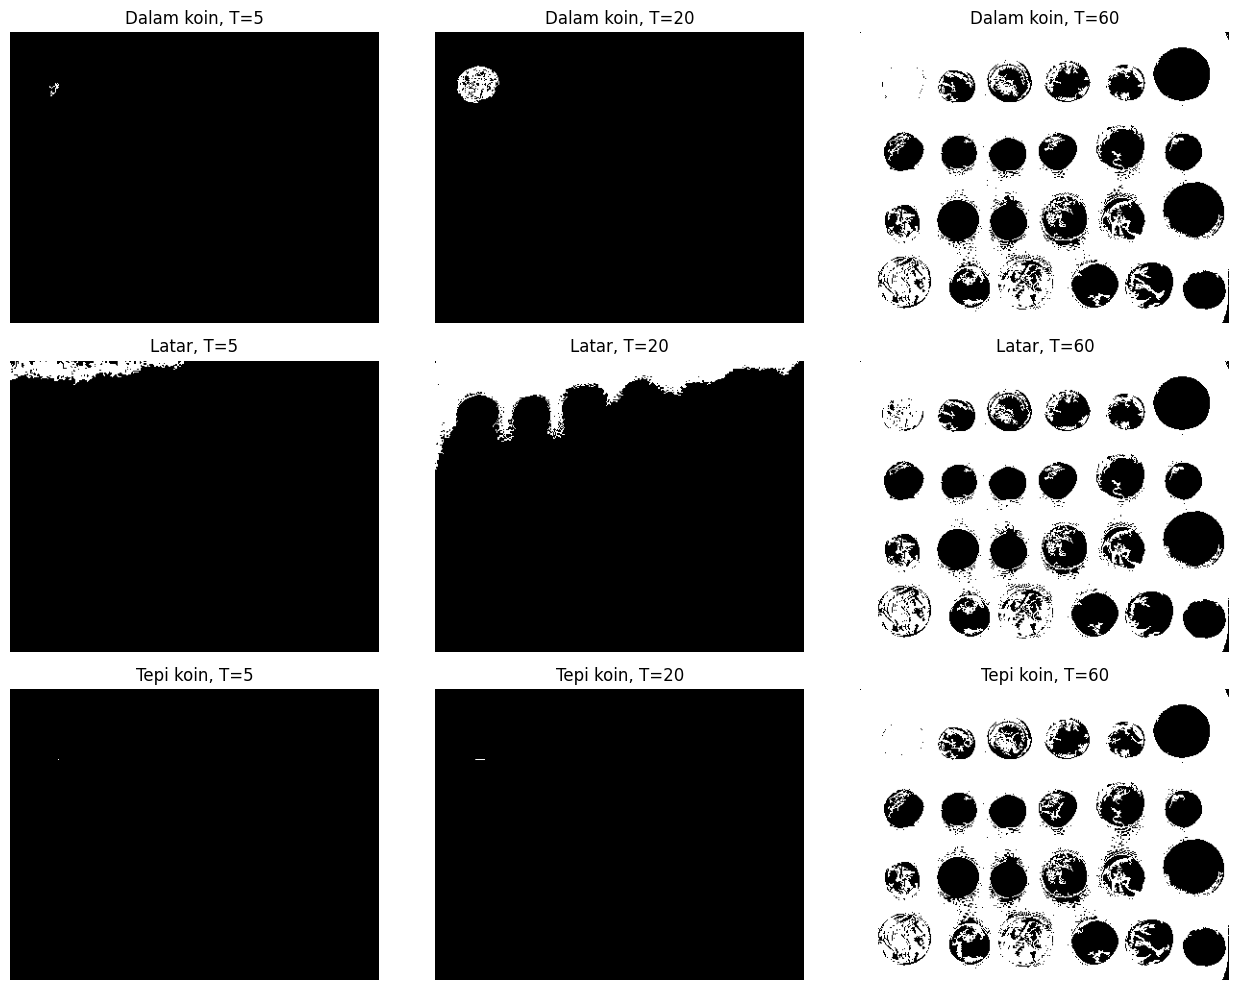

In [16]:
coins = data.coins()

# Posisi seed ditulis sebagai (baris, kolom)
seed_dalam = (55, 50)
seed_latar = (10, 10)
seed_tepi = (73, 50)
seeds = [('Dalam koin', seed_dalam), ('Latar', seed_latar), ('Tepi koin', seed_tepi)]
T_list = [5, 20, 60]

# Menggunakan 8-ketetanggaan seperti penjelasan pada slide
tetangga = [(-1, -1), (-1, 0), (-1, 1), (0, -1),
            (0, 1), (1, -1), (1, 0), (1, 1)]

def region_growing(img, seed, T):
    mask = np.zeros(img.shape, dtype=bool)
    sy, sx = seed
    mask[sy, sx] = True
    antrian = deque([(sy, sx)])
    jumlah_intensitas = int(img[sy, sx])
    jumlah_piksel = 1

    while antrian:
        y, x = antrian.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < img.shape[0] and 0 <= nx < img.shape[1] and not mask[ny, nx]:
                mean_region = jumlah_intensitas / jumlah_piksel
                if abs(int(img[ny, nx]) - mean_region) <= T:
                    mask[ny, nx] = True
                    jumlah_intensitas += int(img[ny, nx])
                    jumlah_piksel += 1
                    antrian.append((ny, nx))
    return mask

plt.figure(figsize=(13, 10))
for i, (nama_seed, seed) in enumerate(seeds):
    for j, T in enumerate(T_list):
        hasil = region_growing(coins, seed, T)
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(hasil, cmap='gray')
        plt.title(nama_seed + ', T=' + str(T))
        plt.axis('off')
plt.tight_layout()
plt.show()


### 6B. Region dengan `skimage.segmentation.flood()`

`flood()` membandingkan intensitas piksel dengan nilai intensitas pada seed, sesuai parameter toleransi.

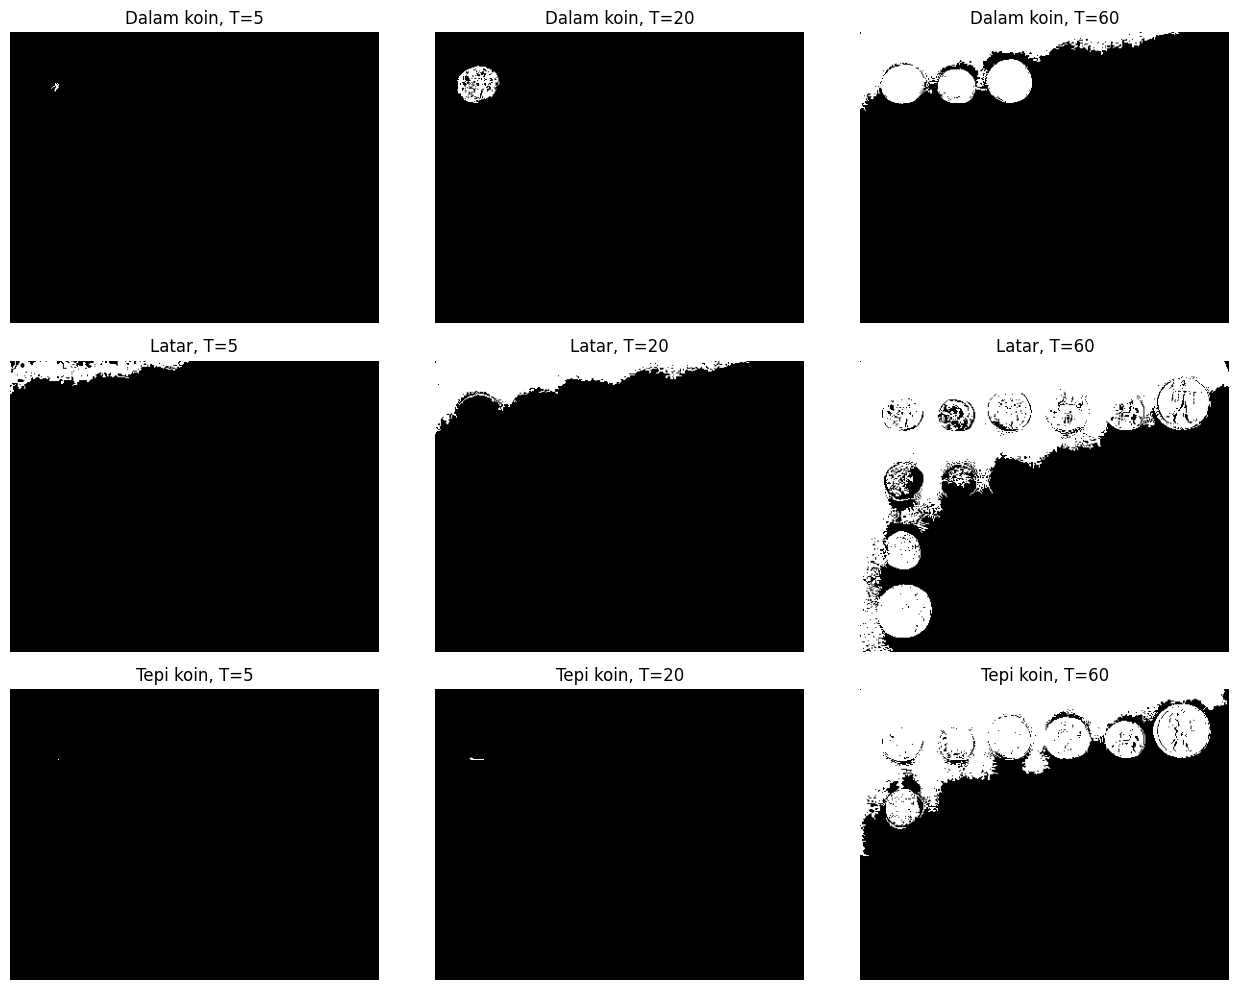

In [17]:
plt.figure(figsize=(13, 10))
for i, (nama_seed, seed) in enumerate(seeds):
    for j, T in enumerate(T_list):
        hasil = flood(coins, seed_point=seed, tolerance=T)
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(hasil, cmap='gray')
        plt.title(nama_seed + ', T=' + str(T))
        plt.axis('off')
plt.tight_layout()
plt.show()


### 7. Segmentasi warna biru pada KTP

Menggunakan rentang HSV yang dicantumkan di modul: H = 85–130, S ≥ 25, V ≥ 40. Piksel dalam rentang dipertahankan dan yang lain dibuat hitam.


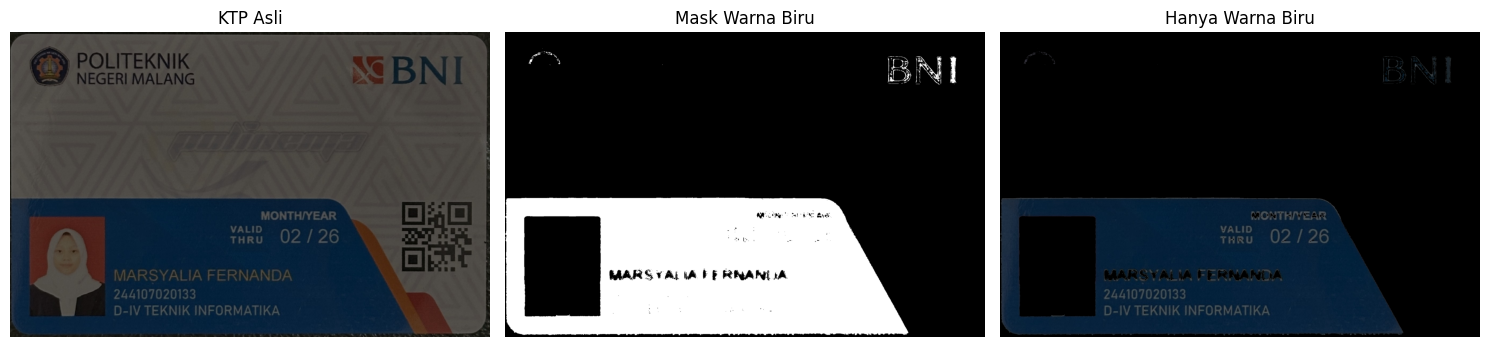

In [18]:
hsv = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2HSV)
H, S, V = cv.split(hsv)

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))
mask_biru = np.zeros(H.shape, dtype=np.uint8)
mask_biru[kelompok_biru] = 255

ktp_biru = cv.bitwise_and(ktp_bgr, ktp_bgr, mask=mask_biru)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB))
plt.title('KTP Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_biru, cmap='gray')
plt.title('Mask Warna Biru')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(ktp_biru, cv.COLOR_BGR2RGB))
plt.title('Hanya Warna Biru')
plt.axis('off')
plt.tight_layout()
plt.show()


### Kesimpulan

Setelah semua sel dijalankan, tulis kesimpulan singkat dengan bahasamu sendiri. Bahas perbedaan lima global threshold, kondisi yang sesuai untuk adaptive threshold, nilai Otsu pada Lena dan KTP, pengaruh seed serta T pada Region Growing, dan apakah rentang HSV sudah menampilkan latar biru KTP dengan baik.